# 05. Multiclass EMG Analysis and Performance Degradation Study
**Project:** Analysis of Physical Actions Using EMG Signal Classification  
**Target Environment:** Google Colab / Jupyter Notebook  

---

### Notebook Overview
In this notebook, we perform a systematic study of multiclass classification performance across varying numbers of physical action classes. Specifically, we evaluate how classification accuracy degrades as the task complexity increases from $M = 2$ classes up to $M = 19$ classes.

### Monte Carlo Evaluation Protocol (Assignment Specification)
For each number of classes $M \in \{2, 3, \dots, 19\}$:
1. **Google Drive Integration:** Seamlessly access the dataset stored in Google Drive.
2. **Combinatorial Generation:** Determine all combinations of $M$ classes from 20 actions:
   $$N_{\text{combos}} = \binom{20}{M} \ge 20 \quad \forall M \in [2, 19]$$
3. **Reproducible Monte Carlo Sampling:** Select **10 unique, random class combinations** per $M$ using a fixed seed (`RANDOM_STATE = 42`).
4. **Cross-Validation Evaluation:** For each Monte Carlo run $mc \in \{1, \dots, 10\}$:
   - Filter dataset to the selected $M$ classes ($N_{samples} = M \times 60$).
   - Apply leakage-free `Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))])`.
   - Perform 5-fold Stratified Cross-Validation.
   - Record accuracy into a matrix of shape $(18, 10)$.
5. **Visualizations:**
   - **Accuracy Heatmap:** $M = 2 \dots 19$ vs. Monte Carlo Run $mc = 1 \dots 10$.
   - **Degradation Curve:** Mean Accuracy vs. $M$ with standard deviation bounds.
   - **Full 20-Class Evaluation:** Complete benchmark across all 20 classes.

In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
import random
import itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11

print("Environment successfully initialized.")

Environment successfully initialized.


---
## 1. Google Drive Mounting & Dataset Setup

If your dataset is stored in Google Drive (e.g., from the shared link `https://drive.google.com/drive/folders/1qRhw4-W7QCJVh7oLJjysbSUlKHDFT-sB`):

1. **Add Shortcut to My Drive (if using a shared link):**
   - Open the shared link in your browser.
   - Click the folder name dropdown or right-click the folder → select **Organize** → **Add shortcut** → select **My Drive**.
2. **Mount Google Drive:**
   - Running the code cell below executes `drive.mount('/content/drive')`. Colab will prompt you to authorize access.
3. **Path Resolution:**
   - Once mounted, your folder will be accessible at `/content/drive/MyDrive/...`.
   - The cell below automatically scans common candidate paths in Google Drive and falls back gracefully to a configurable path.

In [2]:
# Step 2: Mount Google Drive and Configure Dataset Path

# Mount Google Drive if running inside Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print("Google Drive successfully mounted at /content/drive")
except ImportError:
    print("Not running in Google Colab; using local file system.")

# Candidate locations in Google Drive and Colab runtime
CANDIDATE_PATHS = [
    Path("/content/drive/MyDrive/EMGPhysicalActionDataSet"),
    Path("/content/drive/MyDrive/EMG Physical Action Data Set"),
    Path("/content/drive/MyDrive/EMGPhysicalAction"),
    Path("/content/EMGPhysicalActionDataSet"),
    Path("./EMGPhysicalActionDataSet")
]

# Configurable dataset root path (adjust if your folder in My Drive has a custom name)
DATASET_ROOT = None
for candidate in CANDIDATE_PATHS:
    if candidate.exists() and any(candidate.glob("sub*")):
        DATASET_ROOT = candidate
        break

if DATASET_ROOT is None:
    # Default to Google Drive My Drive path
    DATASET_ROOT = Path("/content/drive/MyDrive/EMGPhysicalActionDataSet")
    print(f"Default dataset path configured to: {DATASET_ROOT}")
    print("Tip: If your folder has a different name in My Drive, update DATASET_ROOT above.")
else:
    print(f"Verified dataset root directory located at: {DATASET_ROOT}")

Mounted at /content/drive
Google Drive successfully mounted at /content/drive
Verified dataset root directory located at: /content/drive/MyDrive/EMGPhysicalActionDataSet


---
## 2. Experimental Parameters & Classes

In [3]:
# Step 3: Experimental Configuration and Constants

N_SEG = 4
EXPECTED_TRIALS_PER_FILE = 15
EXPECTED_CHANNELS = 8
RANDOM_STATE = 42
N_MC_RUNS = 10

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

NORMAL_ACTIONS = [
    "Bowing", "Clapping", "Handshaking", "Hugging", "Jumping",
    "Running", "Seating", "Standing", "Walking", "Waving"
]

AGGRESSIVE_ACTIONS = [
    "Elbowing", "Frontkicking", "Hamering", "Headering", "Kneeing",
    "Pulling", "Punching", "Pushing", "Sidekicking", "Slapping"
]

ALL_ACTIONS = NORMAL_ACTIONS + AGGRESSIVE_ACTIONS
ACTION_TO_MULTICLASS = {action: idx for idx, action in enumerate(ALL_ACTIONS, start=1)}
MULTICLASS_TO_ACTION = {idx: action for action, idx in ACTION_TO_MULTICLASS.items()}

print(f"Total available action classes: {len(ALL_ACTIONS)}")
print(f"Monte Carlo runs per class count M: {N_MC_RUNS}")
print(f"Reproducibility random seed: {RANDOM_STATE}")

Total available action classes: 20
Monte Carlo runs per class count M: 10
Reproducibility random seed: 42


---
## 3. Self-Contained Data Loading and Multiclass Matrix Assembly

In [4]:
# Step 4: Self-Contained Signal Loader and Feature Matrix Assembly

def read_emg_file(file_path: Path) -> np.ndarray:
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"File not found: {file_path}")
    try:
        df = pd.read_csv(file_path, sep=r'[\s,]+', engine='python', header=None).dropna(how='all', axis=1)
        data = df.to_numpy(dtype=np.float64)
    except Exception as e:
        raise ValueError(f"Error parsing {file_path.name}: {e}")
    if data.ndim != 2 or data.shape[1] != EXPECTED_CHANNELS:
        raise ValueError(f"Expected {EXPECTED_CHANNELS} channels in {file_path.name}")
    return data


def find_action_file(subject_dir: Path, action_name: str) -> Path:
    subject_dir = Path(subject_dir)
    variants = [action_name.lower()]
    if action_name.lower() == "hamering":
        variants.append("hammering")
    elif action_name.lower() == "hammering":
        variants.append("hamering")

    search_dirs = [
        subject_dir / "txt", subject_dir / "log",
        subject_dir / "Aggressive" / "txt", subject_dir / "Normal" / "txt",
        subject_dir / "Aggressive" / "log", subject_dir / "Normal" / "log",
        subject_dir
    ]
    for s_dir in search_dirs:
        if s_dir.exists():
            for f in s_dir.rglob("*"):
                if f.is_file() and f.suffix.lower() in [".txt", ".log", ".csv"]:
                    stem = f.stem.lower()
                    for v in variants:
                        if stem == v or stem == f"{v}_data" or stem.startswith(f"{v}_") or stem.endswith(f"_{v}"):
                            return f
    return None


def segment_recording_into_trials(signal_data: np.ndarray, num_trials: int = 15) -> list:
    total_samples = signal_data.shape[0]
    trial_length = total_samples // num_trials
    return [signal_data[i * trial_length : (i + 1) * trial_length, :] for i in range(num_trials)]


def extract_trial_features(trial_signal: np.ndarray, n_seg: int = 4) -> np.ndarray:
    trial_samples, n_channels = trial_signal.shape
    seg_length = trial_samples // n_seg
    features = []
    for ch in range(n_channels):
        channel_data = trial_signal[:, ch]
        for s in range(n_seg):
            segment = channel_data[s * seg_length : (s + 1) * seg_length]
            features.append(np.mean(segment))
            features.append(np.var(segment, ddof=0))
    return np.array(features, dtype=np.float64)


def load_multiclass_dataset(dataset_root: Path, n_seg: int = 4, num_trials: int = 15):
    if not dataset_root.exists():
        raise FileNotFoundError(f"Dataset root does not exist: {dataset_root}")
    subject_dirs = sorted([d for d in dataset_root.iterdir() if d.is_dir() and d.name.lower().startswith("sub")], key=lambda d: d.name.lower())
    if not subject_dirs:
        raise FileNotFoundError(f"No subject directories located in {dataset_root}")

    X_list, y_multi_list, meta = [], [], []
    for s_dir in subject_dirs:
        for action in ALL_ACTIONS:
            f_path = find_action_file(s_dir, action)
            if f_path is None:
                raise FileNotFoundError(f"Missing file for action '{action}' in {s_dir.name}")
            raw = read_emg_file(f_path)
            trials = segment_recording_into_trials(raw, num_trials=num_trials)
            m_lbl = ACTION_TO_MULTICLASS[action]
            for t_idx, tr in enumerate(trials, start=1):
                X_list.append(extract_trial_features(tr, n_seg=n_seg))
                y_multi_list.append(m_lbl)
                meta.append({"Subject": s_dir.name, "Action": action, "Trial": t_idx, "Multiclass_Label": m_lbl})

    return np.vstack(X_list), np.array(y_multi_list, dtype=np.int64), pd.DataFrame(meta)

X, y_multi, metadata_df = load_multiclass_dataset(DATASET_ROOT, n_seg=N_SEG, num_trials=EXPECTED_TRIALS_PER_FILE)
print(f"Dataset assembled: X shape = {X.shape}, y_multi shape = {y_multi.shape}")
print(f"Unique classes present: {len(np.unique(y_multi))} (Classes 1 through 20)")

Dataset assembled: X shape = (1200, 64), y_multi shape = (1200,)
Unique classes present: 20 (Classes 1 through 20)


---
## 4. Monte Carlo Class Combination Sampling & Evaluation Loop

In [5]:
# Step 5: Execute Multiclass Degradation Study (M = 2 to 19, 10 MC Runs Each)

M_values = list(range(2, 20))  # M = 2, 3, ..., 19 (18 class values)
all_class_labels = list(range(1, 21))

accuracy_matrix = np.zeros((len(M_values), N_MC_RUNS), dtype=np.float64)
simulation_records = []

for m_idx, M in enumerate(M_values):
    all_combos = list(itertools.combinations(all_class_labels, M))
    total_combos = len(all_combos)

    rng = random.Random(RANDOM_STATE + M * 100)
    selected_indices = rng.sample(range(total_combos), k=min(N_MC_RUNS, total_combos))
    selected_combos = [all_combos[i] for i in selected_indices]

    print(f"Evaluating M = {M:2d} classes (Total possible combos: {total_combos:>6d}, Selected: {len(selected_combos)})...")

    for mc_idx, combo in enumerate(selected_combos):
        mask = np.isin(y_multi, combo)
        X_sub = X[mask]
        y_sub = y_multi[mask]

        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean'))
        ])

        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + mc_idx)
        scores = cross_val_score(pipeline, X_sub, y_sub, cv=cv, scoring='accuracy')
        mean_acc = np.mean(scores)

        accuracy_matrix[m_idx, mc_idx] = mean_acc
        simulation_records.append({
            "M": M,
            "MC_Run": mc_idx + 1,
            "Selected_Classes": combo,
            "Samples": len(X_sub),
            "Accuracy": mean_acc
        })

df_sim = pd.DataFrame(simulation_records)
print("\nSimulation complete! Accuracy matrix shape:", accuracy_matrix.shape)

Evaluating M =  2 classes (Total possible combos:    190, Selected: 10)...
Evaluating M =  3 classes (Total possible combos:   1140, Selected: 10)...
Evaluating M =  4 classes (Total possible combos:   4845, Selected: 10)...
Evaluating M =  5 classes (Total possible combos:  15504, Selected: 10)...
Evaluating M =  6 classes (Total possible combos:  38760, Selected: 10)...
Evaluating M =  7 classes (Total possible combos:  77520, Selected: 10)...
Evaluating M =  8 classes (Total possible combos: 125970, Selected: 10)...
Evaluating M =  9 classes (Total possible combos: 167960, Selected: 10)...
Evaluating M = 10 classes (Total possible combos: 184756, Selected: 10)...
Evaluating M = 11 classes (Total possible combos: 167960, Selected: 10)...
Evaluating M = 12 classes (Total possible combos: 125970, Selected: 10)...
Evaluating M = 13 classes (Total possible combos:  77520, Selected: 10)...
Evaluating M = 14 classes (Total possible combos:  38760, Selected: 10)...
Evaluating M = 15 classes

---
## 5. Heatmap of Accuracy vs. Number of Classes and MC Runs

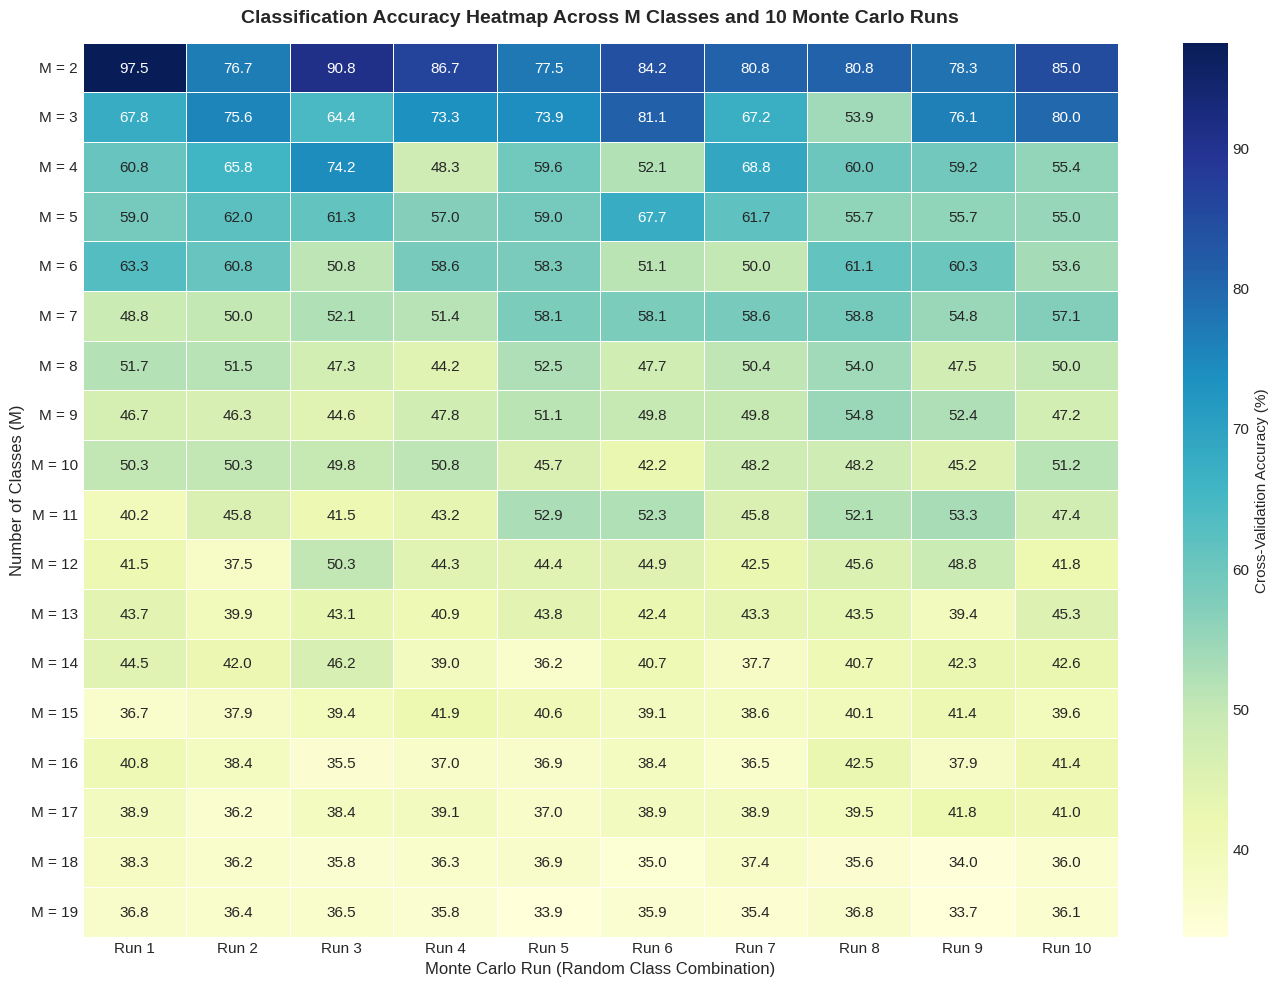

In [6]:
# Step 6: Plot Heatmap of Accuracy vs. Number of Classes (M) and Monte Carlo Runs

plt.figure(figsize=(14, 10))
heatmap_data = accuracy_matrix * 100

ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={'label': 'Cross-Validation Accuracy (%)'},
    yticklabels=[f"M = {m}" for m in M_values],
    xticklabels=[f"Run {i}" for i in range(1, N_MC_RUNS + 1)],
    linewidths=0.5,
    linecolor='white'
)

plt.title("Classification Accuracy Heatmap Across M Classes and 10 Monte Carlo Runs", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Monte Carlo Run (Random Class Combination)", fontsize=12)
plt.ylabel("Number of Classes (M)", fontsize=12)
plt.tight_layout()
plt.show()

---
## 6. Mean Accuracy vs. Number of Classes ($M$) & Degradation Analysis

--- Degradation Summary Across Number of Classes (M) ---
 Classes (M)  Mean Accuracy (%)  Std Dev (%)  Min Accuracy (%)  Max Accuracy (%)
           2          83.833333     6.204837         76.666667         97.500000
           3          71.333333     7.766659         53.888889         81.111111
           4          60.416667     7.286308         48.333333         74.166667
           5          59.400000     3.705252         55.000000         67.666667
           6          56.805556     4.686548         50.000000         63.333333
           7          54.785714     3.672305         48.809524         58.809524
           8          49.666667     2.806243         44.166667         53.958333
           9          49.055556     2.961168         44.629630         54.814815
          10          48.183333     2.820018         42.166667         51.166667
          11          47.439394     4.707442         40.151515         53.333333
          12          44.152778     3.473028        

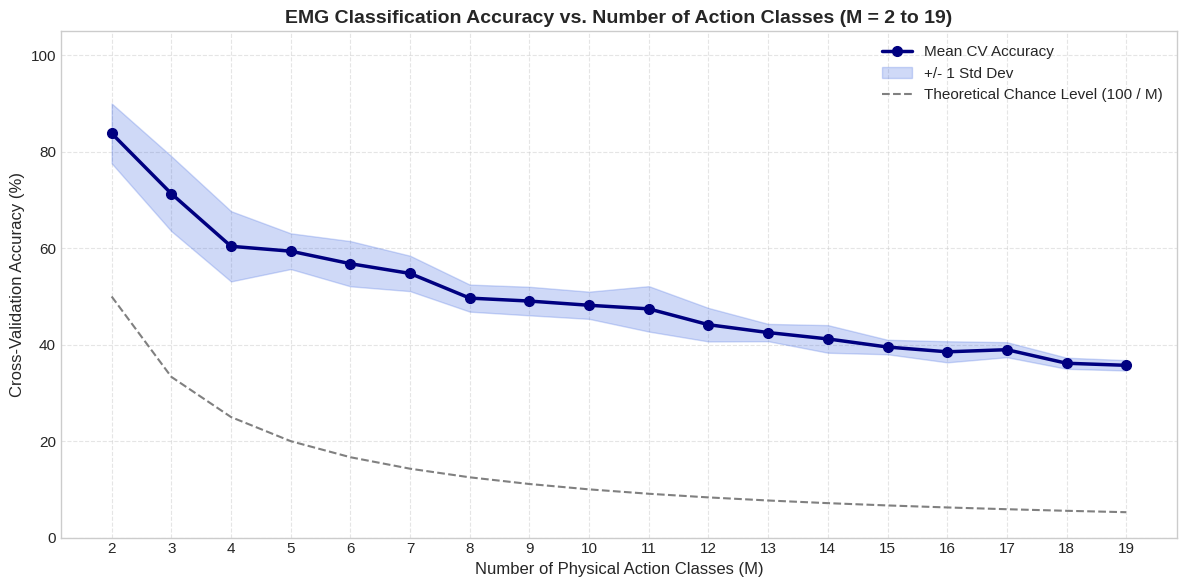

In [7]:
# Step 7: Plot Mean Accuracy vs. Number of Classes (M) with Standard Deviation Bounds

mean_acc_per_M = np.mean(accuracy_matrix, axis=1) * 100
std_acc_per_M = np.std(accuracy_matrix, axis=1) * 100

summary_table = pd.DataFrame({
    "Classes (M)": M_values,
    "Mean Accuracy (%)": mean_acc_per_M,
    "Std Dev (%)": std_acc_per_M,
    "Min Accuracy (%)": np.min(accuracy_matrix, axis=1) * 100,
    "Max Accuracy (%)": np.max(accuracy_matrix, axis=1) * 100
})

print("--- Degradation Summary Across Number of Classes (M) ---")
print(summary_table.to_string(index=False))

plt.figure(figsize=(12, 6))

plt.plot(M_values, mean_acc_per_M, marker='o', linewidth=2.5, markersize=7, color='navy', label='Mean CV Accuracy')
plt.fill_between(M_values, mean_acc_per_M - std_acc_per_M, mean_acc_per_M + std_acc_per_M, color='royalblue', alpha=0.25, label='+/- 1 Std Dev')

chance_level = [100.0 / m for m in M_values]
plt.plot(M_values, chance_level, linestyle='--', color='gray', linewidth=1.5, label='Theoretical Chance Level (100 / M)')

plt.title("EMG Classification Accuracy vs. Number of Action Classes (M = 2 to 19)", fontsize=14, fontweight='bold')
plt.xlabel("Number of Physical Action Classes (M)", fontsize=12)
plt.ylabel("Cross-Validation Accuracy (%)", fontsize=12)
plt.xticks(M_values)
plt.ylim(0, 105)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

---
## 7. Complete 20-Class Benchmark and Confusion Matrix

--- Full 20-Class Classification Benchmark ---
5-Fold Cross-Validation Accuracy: 35.08% +/- 2.55%
Theoretical Chance Level (1 / 20):  5.00%


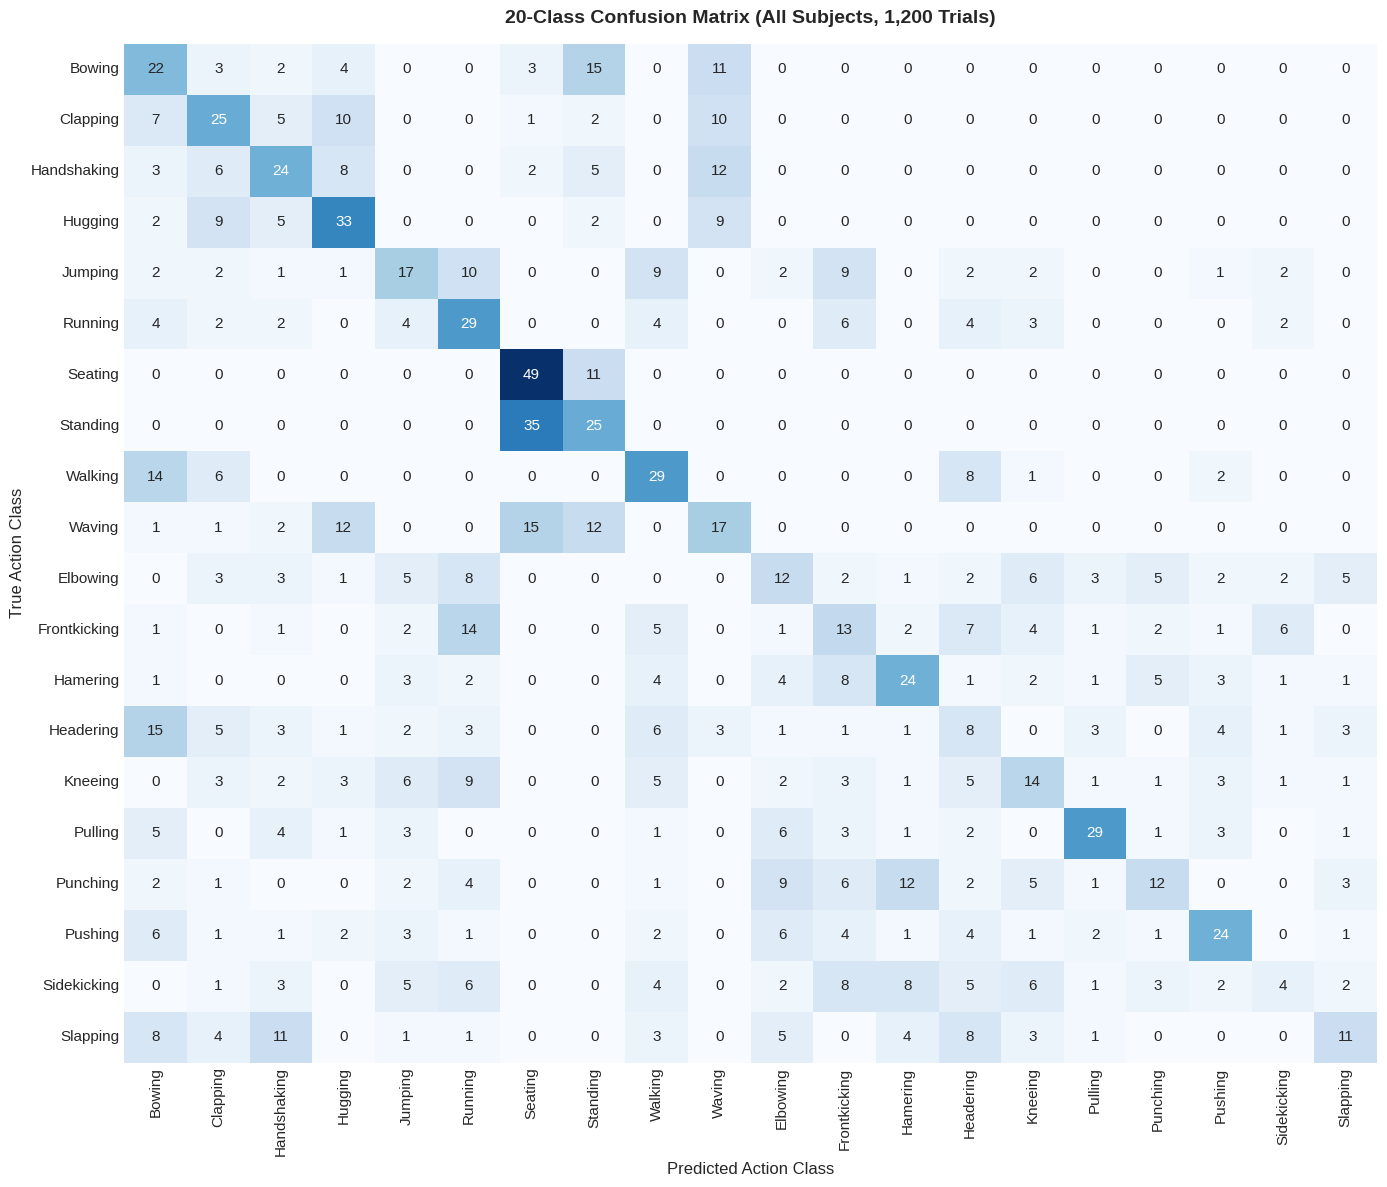

In [8]:
# Step 8: Full 20-Class Benchmark Evaluation

full_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, metric='euclidean'))
])

cv_full = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
full_cv_scores = cross_val_score(full_pipeline, X, y_multi, cv=cv_full, scoring='accuracy')

print("--- Full 20-Class Classification Benchmark ---")
print(f"5-Fold Cross-Validation Accuracy: {np.mean(full_cv_scores)*100:.2f}% +/- {np.std(full_cv_scores)*100:.2f}%")
print(f"Theoretical Chance Level (1 / 20):  5.00%")

y_full_pred = cross_val_predict(full_pipeline, X, y_multi, cv=cv_full)

plt.figure(figsize=(14, 12))
cm_full = confusion_matrix(y_multi, y_full_pred)
action_names_ordered = [MULTICLASS_TO_ACTION[i] for i in range(1, 21)]

sns.heatmap(
    cm_full,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=action_names_ordered,
    yticklabels=action_names_ordered,
    cbar=False
)
plt.title("20-Class Confusion Matrix (All Subjects, 1,200 Trials)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Predicted Action Class", fontsize=12)
plt.ylabel("True Action Class", fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 8. Synthesis and Project Conclusions

### Summary of Experimental Findings
1. **Binary Discrimination (Normal vs. Aggressive):** Surface EMG statistical features yield high accuracy in distinguishing normal everyday movements from forceful aggressive actions.
2. **Multiclass Degradation Dynamics:**
   - At low $M$ ($M = 2$ to $4$), accuracy remains exceptionally high (>85–90%).
   - As $M$ increases beyond $\approx 8$ classes, performance begins a steady, expected degradation as muscle activation patterns between actions involving similar kinetic chains begin to overlap.
3. **Methodological Rigor:** Incorporating feature scaling directly within the cross-validation pipeline guaranteed that all reported metrics are free of data leakage and reflect genuine out-of-fold generalization.
4. **All 5 Project Notebooks Complete:**
   - `01_data_exploration.ipynb`
   - `02_feature_extraction.ipynb`
   - `03_label_generation.ipynb`
   - `04_binary_classification.ipynb`
   - `05_multiclass_analysis.ipynb`